## Introduccion al entorno y a la base de datos


Este primer notebook sera dedicado a hacer una breve introduccion al entorno y un analisis simple sobre los datos.  

### Entorno
En estos notebooks utilizaremos python3 para analizar los datos, trabajando con los siguientes modulos para Data Science:

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import empiricaldist
import sqlite3
import scipy.stats as st
conn = sqlite3.connect("../data/Datos_Limpios.db")


In [3]:
plt.rcParams.update({
    "figure.facecolor": "#121314",
    "axes.facecolor": "#121314",
    "axes.edgecolor": "#FFFFFF",
    "axes.labelcolor": "#FFFFFF",
    "text.color": "#FFFFFF",
    "xtick.color": "#FFFFFF",
    "ytick.color": "#FFFFFF",
    "grid.color": "#2B2B2B",
    "lines.color": "#FFFFFF"
})

### Base de datos

La base de datos que utilizaremos para este proyecto, "Datos_Limpios", esta hecha por mi, utilizando los siguientes datasets: 

Datos partidos mundial 2026:
https://www.kaggle.com/datasets/swaptr/fifa-wc-2026-matches

Elo Ratings Historicos:
https://www.kaggle.com/datasets/saifalnimri/international-football-elo-ratings

Datos partidos mundiales:
https://www.kaggle.com/datasets/joshfjelstul/world-cup-database?

Datos partidos internacionales:
https://www.kaggle.com/datasets/martj42/international-football-results-from-1872-to-2017?

Datos_Limpios contiene dos tipos de tablas:  

- Tablas maestras de identificacion, las cuales permiten ubicar la mayoria de los ID de datos que aparecen en las tablas a su respectivo valor.  

  -teams_master y team_aliases: teams_master contiene el nombre e id por el cual se identifica a cada region la cual esta presente en un partido. En cambio
  team aliases contiene los distintos alias para los que se puede referir a un mismo pais ya presente  en teams_master, junto con su respectivo id de esta misma tabla.  
  -tournament_master: El cual nos permite identificar para unas tablas de partido que tipo de torneo se estaba jugando:

In [4]:
query = "SELECT * FROM teams_master"
tm = pd.read_sql_query(query, conn)
tm

,team_id,canonical_name,fifa_code,confederation
0,1,Afghanistan,AFG,AFC
1,2,Albania,ALB,UEFA
2,3,Algeria,ALG,CAF
3,4,Andorra,AND,UEFA
4,5,Angola,ANG,CAF
...,...,...,...,...
231,232,Palau,PLW,AFC
232,233,São Tomé and Príncipe,NaN,CAF
233,234,Saint Vincent and the Grenadines,NaN,CONCACAF
234,235,Saint Kitts and Nevis,NaN,CONCACAF


In [5]:
query = "SELECT * FROM team_aliases"
ta = pd.read_sql_query(query, conn)
ta

,alias,team_id
0,Czechoslovakia,45
1,West Germany,65
2,Soviet Union,140
3,Yugoslavia,144
4,East Germany,65
...,...,...
115,Sao Tome and Principe,233
116,Germany DR,65
117,Bosnia–Herz,23
118,Cabo Verde,33


In [6]:
query = "SELECT * FROM tournament_master"
ttm = pd.read_sql_query(query, conn)
ttm

,tournament_id,tournament_name,competition_type,region
0,1,FIFA World Cup,World Cup,FIFA
1,2,FIFA World Cup qualification,Qualification,FIFA
2,3,Confederations Cup,International Tournament,FIFA
3,4,FIFA Series,International Tournament,FIFA
4,5,FIFA 75th Anniversary Cup,International Tournament,FIFA
...,...,...,...,...
196,197,South Asian Super Cup,other,NaN
197,198,Al Ain International Cup,other,NaN
198,199,Mukuru 4 Nations,other,NaN
199,200,Diamond Jubilee International Football Tournament,other,NaN


Luego estan las tablas que mas nos interesan, por que son las que nos van a brindar los datos con los que vamos a trabajar:

 -results_shootouts: Contiene todos los partidos internacionales a nivel seleccion que nos interesan para el analisis, incluyendo cualquier torneo o amistoso entre cualquier equipo.  
 -world_cup_matches: Por su nombre, tiene todos los partidos de mundiales, usamos esta tabla para sacar datos de mundiales. Pese a que results_shootouts tambien tiene todos los partidos de mundiales, world_cup_matches es mas completo en datos que nos brinda.  
 -eloratings_clean: La cual contiene el historial de cambios de puntaje elo FIFA para todas las selecciones. Ahora no lo usaremos mucho, pero lo tomaremos para prediccion.

In [7]:
query = "SELECT * FROM world_cup_matches"
wcm = pd.read_sql_query(query, conn)
wcm

,match_id,date,home_team,home_team_id,away_team,away_team_id,round,home_score,away_score,neutral,...,away_xg,home_possession,away_possession,home_sot,away_sot,home_shots,away_shots,result,away_is_local,home_is_local
0,1408,1930-07-13,United States,175,Belgium,17,Group stage,3,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,home team win,0,0
1,1409,1930-07-13,France,61,Mexico,110,Group stage,4,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,home team win,0,0
2,1410,1930-07-14,Yugoslavia,144,Brazil,25,Group stage,2,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,home team win,0,0
3,1411,1930-07-14,Romania,139,Peru,134,Group stage,3,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,home team win,0,0
4,1412,1930-07-15,Argentina,7,France,61,Group stage,1,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,home team win,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1063,48061,2026-07-11,Norway,127,England,53,Quarter-finals,1,2,1,...,0.96,48.0,52.0,4.0,8.0,13.0,14.0,away team win,0,0
1064,48062,2026-07-14,France,61,Spain,155,Semi-finals,0,2,1,...,1.63,49.0,51.0,3.0,2.0,10.0,10.0,away team win,0,0
1065,48063,2026-07-15,England,53,Argentina,7,Semi-finals,1,2,1,...,1.80,36.0,64.0,2.0,5.0,5.0,15.0,away team win,0,0
1066,48064,2026-07-18,France,61,England,53,Third-place match,4,6,1,...,2.88,46.0,54.0,9.0,11.0,19.0,19.0,away team win,0,0


In [8]:
query = "SELECT * FROM results_shootouts"
rs = pd.read_sql_query(query, conn)
rs

,match_id,date,home_team,away_team,home_team_id,away_team_id,home_score,away_score,neutral,country,...,has_shootouts,winner_on_shootouts,winner,tournament,tournament_id,result,local_team_id,local,away_is_local,home_is_local
0,3204,1950-01-24,Zambia,DR Congo,183,194,1,0,0,Northern Rhodesia,...,0,NaN,Zambia,Friendly,97,home team win,183.0,home team,0,1
1,3205,1950-02-17,Egypt,Greece,51,67,2,0,0,Egypt,...,0,NaN,Egypt,Friendly,97,home team win,51.0,home team,0,1
2,3206,1950-02-26,Bolivia,Chile,22,36,2,0,0,Bolivia,...,0,NaN,Bolivia,Friendly,97,home team win,22.0,home team,0,1
3,3207,1950-02-26,Croatia,Serbia,42,144,4,1,0,Yugoslavia,...,0,NaN,Croatia,Friendly,97,home team win,144.0,away team,1,0
4,3208,1950-03-05,Italy,Belgium,84,17,3,1,0,Italy,...,0,NaN,Italy,Friendly,97,home team win,84.0,home team,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44857,48061,2026-07-11,Norway,England,127,53,1,2,1,United States,...,0,NaN,England,FIFA World Cup,1,away team win,NaN,NaN,0,0
44858,48062,2026-07-14,France,Spain,61,155,0,2,1,United States,...,0,NaN,Spain,FIFA World Cup,1,away team win,NaN,NaN,0,0
44859,48063,2026-07-15,England,Argentina,53,7,1,2,1,United States,...,0,NaN,Argentina,FIFA World Cup,1,away team win,NaN,NaN,0,0
44860,48064,2026-07-18,France,England,61,53,4,6,1,United States,...,0,NaN,England,FIFA World Cup,1,away team win,NaN,NaN,0,0


In [9]:
query = "SELECT * FROM eloratings_clean"
elos = pd.read_sql_query(query, conn)
elos

,date,team,rating,change,team_id
0,1872-11-30,England,2003,3,53.0
1,1872-11-30,Scotland,1997,-3,185.0
2,1873-03-08,England,2014,11,53.0
3,1873-03-08,Scotland,1986,-11,185.0
4,1874-03-07,England,2006,-8,53.0
...,...,...,...,...,...
6673,2025-12-13,Northern Mariana Islands,432,0,230.0
6674,2025-12-13,Cocos Islands,422,0,231.0
6675,2025-12-13,Palau,402,0,232.0
6676,2025-12-13,Eastern Samoa,389,0,214.0


Con esto podemos ya empezar a hacer unos breves analisis para empezar

## Evolucion de goles por edicion



Para empezar, me gustaria ver como ha cambiado la cantidad de goles que se ven por partidos a medida que ha avanzado el deporte. 
Para eso, utilicemos world_cup_matches (wcm):  
Podemos obtener cada edicion mundialista agrupando wcm por año con la columna date.
La columna date de wcm esta guardada como un string del tipo "año-mes-dia", pasemosla a formato Date de pandas para trabajar con esta correctamente.
Luego filtremos el ultimo año de mundial:

In [10]:
wcm["date"] = pd.to_datetime(wcm["date"])

wcm_2026 = wcm[wcm["date"].dt.year == 2026].copy()

wcm_2026

,match_id,date,home_team,home_team_id,away_team,away_team_id,round,home_score,away_score,neutral,...,away_xg,home_possession,away_possession,home_sot,away_sot,home_shots,away_shots,result,away_is_local,home_is_local
964,47962,2026-06-11,South Korea,153,Czech Republic,45,Group stage,2,1,1,...,1.12,62.0,38.0,6.0,4.0,15.0,7.0,home team win,0,0
965,47963,2026-06-11,Mexico,110,South Africa,152,Group stage,2,0,0,...,0.52,61.0,40.0,4.0,2.0,16.0,3.0,home team win,0,1
966,47964,2026-06-12,Canada,32,Bosnia and Herzegovina,23,Group stage,1,1,0,...,0.98,61.0,39.0,4.0,3.0,13.0,8.0,draw,0,1
967,47965,2026-06-12,United States,175,Paraguay,133,Group stage,4,1,0,...,0.88,65.0,35.0,6.0,1.0,16.0,9.0,home team win,0,1
968,47966,2026-06-13,Australia,9,Turkey,170,Group stage,2,0,1,...,0.72,28.0,72.0,4.0,8.0,9.0,30.0,home team win,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1063,48061,2026-07-11,Norway,127,England,53,Quarter-finals,1,2,1,...,0.96,48.0,52.0,4.0,8.0,13.0,14.0,away team win,0,0
1064,48062,2026-07-14,France,61,Spain,155,Semi-finals,0,2,1,...,1.63,49.0,51.0,3.0,2.0,10.0,10.0,away team win,0,0
1065,48063,2026-07-15,England,53,Argentina,7,Semi-finals,1,2,1,...,1.80,36.0,64.0,2.0,5.0,5.0,15.0,away team win,0,0
1066,48064,2026-07-18,France,61,England,53,Third-place match,4,6,1,...,2.88,46.0,54.0,9.0,11.0,19.0,19.0,away team win,0,0


Podemos corroborar que es correcto por que el ultimo mundial tuvo 104 partidos, cada uno representado por una fila de este subquery. Ahora fijemonos en los goles de esta edicion, que en las tablas de resultados de partido estan en las columnas home_score y away_score (cuentan goles en tiempo jugado, no penales).  
Para obtener correctamente la suma de todos los goles por partido, lo que tendriamos que hacer es obtener una serie que contenga por cada partido, la suma de home_score + away_score para ese partido.  
Creemos una columna que represente este valor para cada partido:

In [11]:
wcm_2026["goles"] = wcm_2026["home_score"] + wcm_2026["away_score"]
wcm_2026["goles"].count(), wcm_2026["goles"].sum()

(np.int64(104), np.int64(308))

La suma total de los elementos de goles seria la cantidad de goles en toda la edicion mundialista.  
Como nos interesa comparar este mundial con otros para visualizar como ha cambiado la frecuencia de goles, no podemos simplemente evaluar la cantidad total de goles porque las ediciones varian en cantidad de partidos. Justamente esta ultima edicion es la que contiene la mayor cantidad de partidos, 104.  

Por lo cual seria mas confiable verificar la cantidad de goles por partido para cada edicion. En esta, el promedio es 2.96

In [12]:
wcm_2026["goles"].mean()

np.float64(2.9615384615384617)

Siguiendo estos pasos, podemos crear un DataFrame de Pandas que contenga estos datos por cada edicion mundialista:   

Ajustamos "manualmente" los indices de este dataframe para que respete la cronologia de 4 años por edicion mundialista, de este modo podemos evitar asignar valores a los años en los que no hubieron ediciones (1942 y 1946).  


In [21]:
wcm["goles"] = wcm["home_score"] + wcm["away_score"]

goles_por_edicion = (
      wcm.groupby(wcm["date"].dt.year)["goles"]
         .agg(promedio="mean", total="sum", cant_partidos="count")
         .round({"promedio": 2})
         .reset_index()
         .rename(columns={"date": "Edicion"})
  )
goles_por_edicion = goles_por_edicion.set_index("Edicion").reindex(range(1930, 2027, 4)).reset_index()
goles_por_edicion

,Edicion,promedio,total,cant_partidos
0,1930,3.89,70.0,18.0
1,1934,4.12,70.0,17.0
2,1938,4.67,84.0,18.0
3,1942,NaN,NaN,NaN
4,1946,NaN,NaN,NaN
5,1950,4.00,88.0,22.0
6,1954,5.38,140.0,26.0
7,1958,3.60,126.0,35.0
8,1962,2.78,89.0,32.0
9,1966,2.78,89.0,32.0


Algo interesante es la diferencia que hay en la cantidad de partidos por edicion.  
Por ejemplo, las primeras ediciones tuvieron 17-18 partidos, y este numero fue creciendo progresivamente hasta 2026 donde pego el salto de 64 a 104 partidos.   

Esto implica que los datos de las primeras ediciones mundialistas con respecto a goles tendran mayor variabilidad dada su muestra reducida.  

Luego, con estos datos podriamos crear una simple serie temporal con datos discretos, utilizando el promedio de goles:

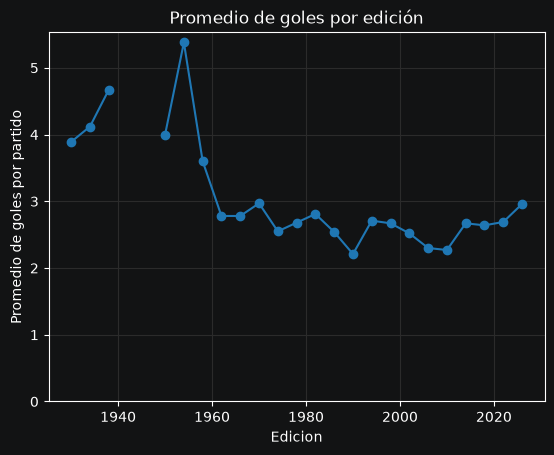

In [22]:
plt.plot(
    goles_por_edicion["Edicion"],
    goles_por_edicion["promedio"],
    marker="o"
)

plt.xlabel("Edicion")
plt.ylabel("Promedio de goles por partido")
plt.title("Promedio de goles por edición")
plt.ylim(bottom=0)
plt.grid()
plt.show()


Ahora es mas facil visualizar la tendencia, desde 1930 hasta aprox 1958, el promedio de goles por partido ha variado mucho entre aproximadamente 3.6 y 5.4. Consiguiendo un peculiar maximo en 1954 con 5.38.  

 Como ya explicamos, esta variabilidad se puede deber al bajo tamaño de muestra que presentan estas ediciones.   
Tambien en esa seccion de la serie temporal podemos ver el corte dado a las ediciones no jugadas.  

En 1962 cayo a 2.78, desde ahi empezo a variar en menor magnitud, alcanzando dos minimos en 1990(2.21) y 2010(2.27), pero permaneciendo la mayoria de las veces entre 2.2 y 2.9.

Con estos datos podemos tambien calcular un intervalo de confianza de 95% del promedio de goles por cada partido, de este modo podremos dimensionar mejor la variabilidad dada por el menor tamaño de muestra en las primeras ediciones, y como ha cambiado a lo largo del tiempo.  

El intervalo de confianza del 95% del promedio de goles por partido lo podemos obtener modelando los goles totales de cada edicion con una distribucion Poisson.  
Con esto ultimo suponemos que los goles son independientes entre si y que ocurren a un ritmo promedio constante, es decir, que todos los partidos de una edicion tienen el mismo promedio esperado de goles. Es una simplificacion, que tomaremos para este analisis.

Con esto, estimamos lambda como k/n (goles totales sobre cantidad de partidos) y obtenemos los limites del IC 95% con los cuantiles de la distribucion chi-cuadrado, que da el intervalo exacto para un conteo de Poisson. Luego dividimos esos limites por la cantidad de partidos para expresarlos como promedio de goles por partido

In [23]:
df = goles_por_edicion.copy()

alpha = 0.05   # 95% de confianza

k = df["total"]
n = df["cant_partidos"]

# limites superior e inferior del IC 95
limite_inf_total = st.chi2.ppf(alpha / 2, 2 * k) / 2
limite_sup_total = st.chi2.ppf(1 - alpha / 2, 2 * (k + 1)) / 2

# promediamos
df["ic_inf"] = limite_inf_total / n
df["ic_sup"] = limite_sup_total / n

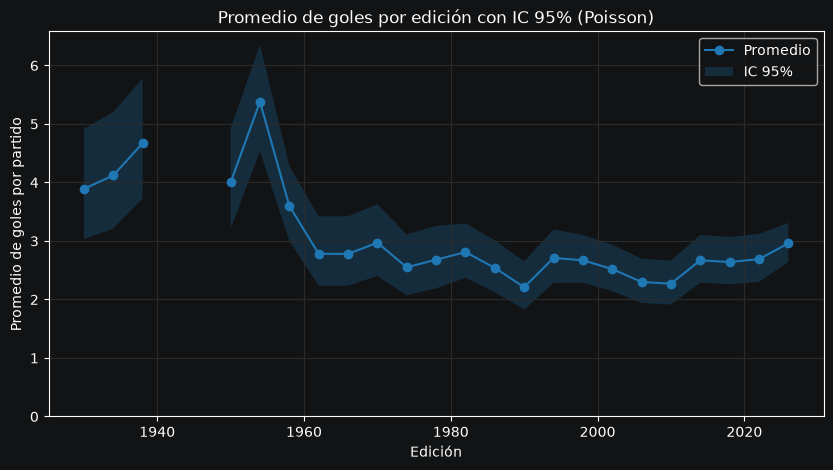

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(df["Edicion"], df["promedio"], marker="o", label="Promedio")
plt.fill_between(df["Edicion"], df["ic_inf"], df["ic_sup"],
                 alpha=0.25, label="IC 95%")
                 
plt.xlabel("Edición")
plt.ylabel("Promedio de goles por partido")
plt.title("Promedio de goles por edición con IC 95% (Poisson)")
plt.ylim(bottom=0)
plt.legend()
plt.grid()
plt.show()

En este plot podemos ver bastante mejor como en las primeras ediciones mundialistas la variabilidad o error estandar son muchos mas grandes, llegando a tener un rango de casi 2 goles por partido en esas ediciones, podemos ver tambien como a medida que van pasando las ediciones y el tamaño de muestra aumenta, la variabilidad de los promedios es mucho menor.   
Aun que pueda ayudar, la variabilidad no termina de explicar la evolucion de promedio de goles por edicion, la bajada en promedio desde 1954 hasta estabilizarse en 1962 puede que se explique por los avances tacticos de esa epoca en adelante, o un cambio de formato.